layered map

In [17]:
import geopandas as gpd

print("GeoPandas installed successfully!")
print("Version:", gpd.__version__)

GeoPandas installed successfully!
Version: 1.2.0


In [32]:
import pandas as pd

death_df = pd.read_csv("CombinedDeathRatesByCommunityDistrict2023.csv")

death_df

,commntydst,Total_population,Total_Deaths,Death_Rate,Population_65_Plus,Deaths_65_Plus,Crude_Death_Rate_65_Plus,Age_Adjusted_Death_Rate_65_Plus
0,101,78390,181,2.308968,6848,142,20.735981,19.404214
1,102,92445,398,4.305263,14958,331,22.128627,26.647346
2,103,163141,1287,7.888881,30371,947,31.181061,30.112012
3,104,131351,677,5.154129,19231,433,22.515730,26.709509
4,105,63600,254,3.993711,8445,175,20.722321,22.132222
5,106,155614,743,4.774635,29114,615,21.123858,19.169494
6,107,222129,1470,6.617776,47298,1189,25.138484,23.696189
7,108,231983,1449,6.246147,49343,1161,23.529173,20.734793
8,109,110458,644,5.830270,15694,416,26.506945,28.114425
9,110,130440,948,7.267709,16254,548,33.714778,35.930369


In [33]:
death_df.columns.tolist()

['commntydst',
 'Total_population',
 'Total_Deaths',
 'Death_Rate',
 'Population_65_Plus',
 'Deaths_65_Plus',
 'Crude_Death_Rate_65_Plus',
 'Age_Adjusted_Death_Rate_65_Plus']

In [34]:
death_df.head(10)

,commntydst,Total_population,Total_Deaths,Death_Rate,Population_65_Plus,Deaths_65_Plus,Crude_Death_Rate_65_Plus,Age_Adjusted_Death_Rate_65_Plus
0,101,78390,181,2.308968,6848,142,20.735981,19.404214
1,102,92445,398,4.305263,14958,331,22.128627,26.647346
2,103,163141,1287,7.888881,30371,947,31.181061,30.112012
3,104,131351,677,5.154129,19231,433,22.515730,26.709509
4,105,63600,254,3.993711,8445,175,20.722321,22.132222
5,106,155614,743,4.774635,29114,615,21.123858,19.169494
6,107,222129,1470,6.617776,47298,1189,25.138484,23.696189
7,108,231983,1449,6.246147,49343,1161,23.529173,20.734793
8,109,110458,644,5.830270,15694,416,26.506945,28.114425
9,110,130440,948,7.267709,16254,548,33.714778,35.930369


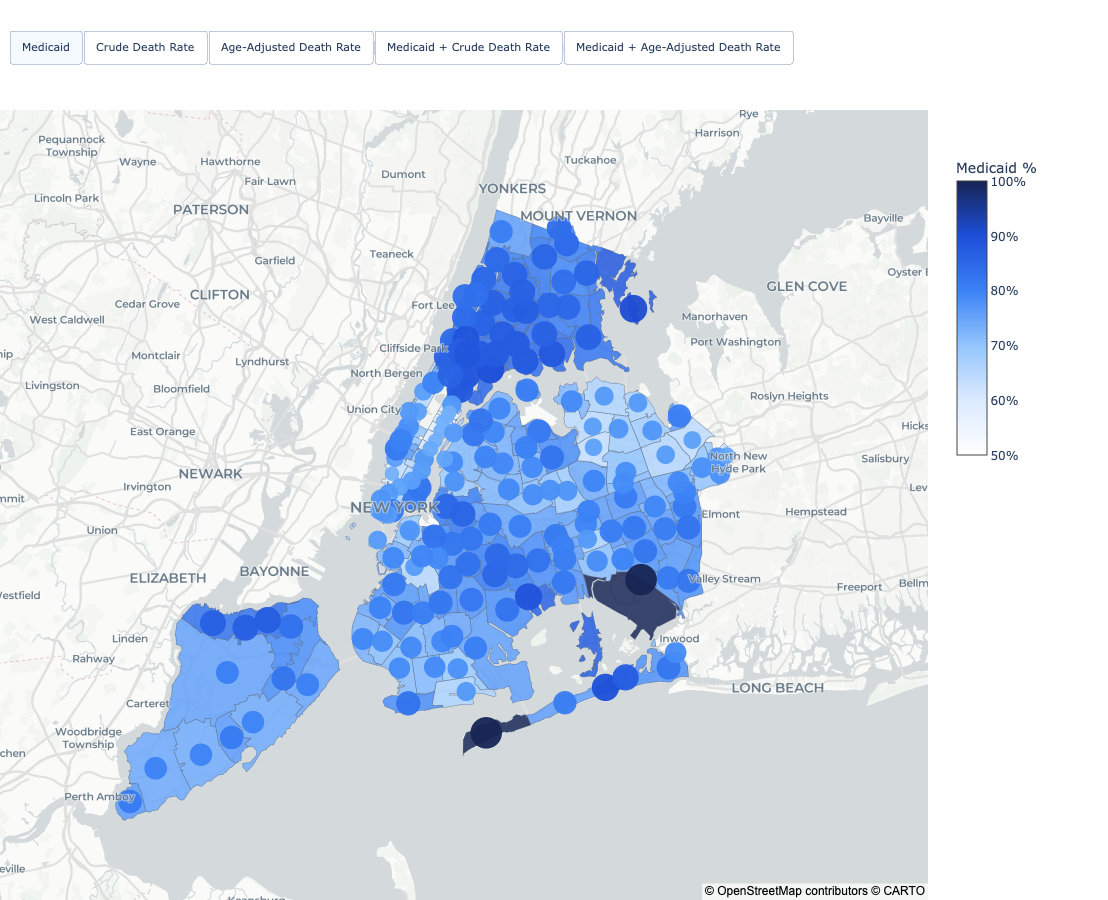

ZIP codes mapped: 181
Community districts mapped: 59
Geographic overlap polygons: 417
Medicaid hover dots: 181
Community district hover dots: 59


In [50]:
import pandas as pd
import numpy as np
import geopandas as gpd
import json
import plotly.graph_objects as go

from shapely import wkt
from pathlib import Path

ENROLLMENT_FILE = "NYC_Program_Enrollment_by_ZIP.csv"
ZIP_GEOJSON_FILE = "nyc-zip-code-tabulation-areas-polygons.geojson"
DISTRICT_GEOJSON_FILE = "nyc_districts.geojson"
DISTRICT_CSV_FILE = "communitydistricts.csv"
DEATH_RATE_FILE = "CombinedDeathRatesByCommunityDistrict2023.csv"

insurance = pd.read_csv(
    ENROLLMENT_FILE,
    dtype={"Zip_Code": "string"}
)

rates = pd.read_csv(DEATH_RATE_FILE)

insurance.columns = insurance.columns.str.strip()
rates.columns = rates.columns.str.strip()

insurance["Zip_Code"] = (
    insurance["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

programs = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_cols = [
    f"{program} Count"
    for program in programs
]

insurance[count_cols] = (
    insurance[count_cols]
    .replace(",", "", regex=True)
    .apply(pd.to_numeric, errors="coerce")
)

insurance = insurance.dropna(
    subset=count_cols
)

insurance = (
    insurance.groupby(
        "Zip_Code",
        as_index=False
    )[count_cols].sum()
)

insurance["Total_Enrollments"] = (
    insurance[count_cols].sum(axis=1)
)

insurance = insurance[
    insurance["Total_Enrollments"] > 0
].copy()

for program in programs:

    insurance[f"{program} Percentage"] = (
        insurance[f"{program} Count"]
        / insurance["Total_Enrollments"]
        * 100
    )

zip_gdf = gpd.read_file(
    ZIP_GEOJSON_FILE
)

zip_gdf["Zip_Code"] = (
    zip_gdf["postalCode"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

zip_gdf = zip_gdf.to_crs(
    "EPSG:4326"
)

zip_gdf = zip_gdf[
    zip_gdf.geometry.notna()
    & zip_gdf.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

zip_gdf = zip_gdf[
    ["Zip_Code", "geometry"]
].dissolve(
    by="Zip_Code",
    as_index=False
)

zip_gdf = zip_gdf.merge(
    insurance,
    on="Zip_Code",
    how="inner",
    validate="one_to_one"
)

zip_geojson_clean = json.loads(
    zip_gdf[
        ["Zip_Code", "geometry"]
    ].to_json()
)

district_gdf = gpd.read_file(
    DISTRICT_GEOJSON_FILE
)

has_polygons = district_gdf.geom_type.isin(
    ["Polygon", "MultiPolygon"]
).any()

if not has_polygons:

    cd_csv = pd.read_csv(
        DISTRICT_CSV_FILE
    )

    cd_csv.columns = cd_csv.columns.str.strip()

    district_gdf = gpd.GeoDataFrame(
        cd_csv,
        geometry=cd_csv["the_geom"].apply(
            lambda x: wkt.loads(x)
            if pd.notna(x) else None
        ),
        crs="EPSG:4326"
    )

if "commntydst" not in district_gdf.columns:

    for candidate in [
        "boro_cd",
        "BoroCD",
        "BORO_CD"
    ]:

        if candidate in district_gdf.columns:

            district_gdf = district_gdf.rename(
                columns={
                    candidate: "commntydst"
                }
            )

            break

district_gdf["commntydst"] = pd.to_numeric(
    district_gdf["commntydst"],
    errors="coerce"
)

district_gdf = district_gdf.dropna(
    subset=["commntydst", "geometry"]
)

district_gdf["commntydst"] = (
    district_gdf["commntydst"].astype(int)
)

district_gdf = district_gdf[
    district_gdf.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

district_gdf = district_gdf.to_crs(
    "EPSG:4326"
)

district_gdf = district_gdf[
    ["commntydst", "geometry"]
].dissolve(
    by="commntydst",
    as_index=False
)

metric_columns = [
    "Total_population",
    "Total_Deaths",
    "Death_Rate",
    "Population_65_Plus",
    "Deaths_65_Plus",
    "Crude_Death_Rate_65_Plus",
    "Age_Adjusted_Death_Rate_65_Plus"
]

rates["commntydst"] = pd.to_numeric(
    rates["commntydst"],
    errors="coerce"
)

rates = rates.dropna(
    subset=["commntydst"]
).copy()

rates["commntydst"] = (
    rates["commntydst"].astype(int)
)

for column in metric_columns:

    rates[column] = pd.to_numeric(
        rates[column]
        .astype(str)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

district_gdf = district_gdf.merge(
    rates,
    on="commntydst",
    how="inner",
    validate="one_to_one"
)

if district_gdf.empty:

    raise ValueError(
        "No community districts matched the mortality dataset."
    )

borough_names = {
    1: "Manhattan",
    2: "Bronx",
    3: "Brooklyn",
    4: "Queens",
    5: "Staten Island"
}

district_gdf["Borough"] = (
    district_gdf["commntydst"] // 100
).map(borough_names)

district_gdf["District_Number"] = (
    district_gdf["commntydst"] % 100
)

district_gdf["District_Label"] = (
    district_gdf["Borough"]
    + " CD "
    + district_gdf["District_Number"].astype(str)
)

district_gdf["commntydst"] = (
    district_gdf["commntydst"].astype(str)
)

district_geojson_clean = json.loads(
    district_gdf[
        ["commntydst", "geometry"]
    ].to_json()
)

zip_projected = zip_gdf[
    [
        "Zip_Code",
        "Medicaid Count",
        "Medicaid Percentage",
        "Total_Enrollments",
        "geometry"
    ]
].to_crs("EPSG:2263")

district_projected = district_gdf[
    [
        "commntydst",
        "District_Label",
        "Total_population",
        "Total_Deaths",
        "Death_Rate",
        "Population_65_Plus",
        "Deaths_65_Plus",
        "Crude_Death_Rate_65_Plus",
        "Age_Adjusted_Death_Rate_65_Plus",
        "geometry"
    ]
].to_crs("EPSG:2263")

intersection = gpd.overlay(
    zip_projected,
    district_projected,
    how="intersection",
    keep_geom_type=True
)

intersection["Intersection_Area"] = (
    intersection.geometry.area
)

intersection = intersection[
    intersection["Intersection_Area"] > 0
].copy()

intersection = intersection.reset_index(
    drop=True
)

intersection["Overlap_ID"] = (
    intersection.index.astype(str)
)

rate_columns = [
    "Crude_Death_Rate_65_Plus",
    "Age_Adjusted_Death_Rate_65_Plus"
]

rate_min = district_gdf[
    rate_columns
].min().min()

rate_max = district_gdf[
    rate_columns
].max().max()

intersection["Medicaid_Intensity"] = (
    (
        intersection["Medicaid Percentage"] - 50
    ) / 50
).clip(0, 1)

if rate_max > rate_min:

    intersection["Mortality_Intensity"] = (
        (
            intersection["Age_Adjusted_Death_Rate_65_Plus"]
            - rate_min
        ) / (rate_max - rate_min)
    ).clip(0, 1)

else:

    intersection["Mortality_Intensity"] = 0.0

intersection["Overlap_Score"] = (
    intersection["Medicaid_Intensity"]
    * intersection["Mortality_Intensity"]
    * 100
)

intersection.loc[
    intersection[
        "Age_Adjusted_Death_Rate_65_Plus"
    ].isna(),
    "Overlap_Score"
] = np.nan

intersection_points = (
    intersection.geometry
    .representative_point()
    .to_crs("EPSG:4326")
)

intersection["lat"] = (
    intersection_points.y.to_numpy()
)

intersection["lon"] = (
    intersection_points.x.to_numpy()
)

intersection = intersection.to_crs(
    "EPSG:4326"
)

overlap_gdf = intersection.dropna(
    subset=["Overlap_Score"]
).copy()

overlap_geojson = json.loads(
    overlap_gdf[
        ["Overlap_ID", "geometry"]
    ].to_json()
)

zip_dots = (
    intersection
    .sort_values(
        "Intersection_Area",
        ascending=False
    )
    .drop_duplicates(
        subset=["Zip_Code"]
    )
    .copy()
)

district_dots = (
    intersection
    .sort_values(
        "Intersection_Area",
        ascending=False
    )
    .drop_duplicates(
        subset=["commntydst"]
    )
    .copy()
)

medicaid_colors = [
    [0.00, "#FFFFFF"],
    [0.20, "#DBEAFE"],
    [0.40, "#93C5FD"],
    [0.60, "#3B82F6"],
    [0.80, "#1D4ED8"],
    [1.00, "#172554"]
]

crude_colors = [
    [0.00, "#FFF5F5"],
    [0.25, "#FECACA"],
    [0.50, "#F87171"],
    [0.75, "#DC2626"],
    [1.00, "#7F1D1D"]
]

adjusted_colors = [
    [0.00, "#FEFCE8"],
    [0.25, "#FEF08A"],
    [0.50, "#FDE047"],
    [0.75, "#EAB308"],
    [1.00, "#A16207"]
]

green_colors = [
    [0.00, "#F0FDF4"],
    [0.20, "#DCFCE7"],
    [0.40, "#86EFAC"],
    [0.60, "#22C55E"],
    [0.80, "#15803D"],
    [1.00, "#14532D"]
]

blue_dot_colors = [
    [0.00, "#93C5FD"],
    [0.25, "#60A5FA"],
    [0.50, "#3B82F6"],
    [0.75, "#1D4ED8"],
    [1.00, "#172554"]
]

red_dot_colors = [
    [0.00, "#FCA5A5"],
    [0.25, "#F87171"],
    [0.50, "#EF4444"],
    [0.75, "#DC2626"],
    [1.00, "#7F1D1D"]
]

yellow_dot_colors = [
    [0.00, "#FEF08A"],
    [0.25, "#FDE047"],
    [0.50, "#FACC15"],
    [0.75, "#EAB308"],
    [1.00, "#A16207"]
]

def calculate_dot_sizes(
    values,
    minimum,
    maximum,
    min_size=8,
    max_size=32
):

    if maximum > minimum:

        normalized = (
            (values - minimum)
            / (maximum - minimum)
        ).clip(0, 1)

        return np.sqrt(
            min_size**2
            + normalized
            * (max_size**2 - min_size**2)
        )

    return np.full(
        len(values),
        (min_size + max_size) / 2
    )

fig = go.Figure()

insurance_hover_cols = [
    "Zip_Code",
    "Total_Enrollments",
    "Medicaid Count",
    "Medicaid Percentage",
    "CHP Count",
    "CHP Percentage",
    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",
    "QHP Full Pay Count",
    "QHP Full Pay Percentage",
    "Essential Plan Count",
    "Essential Plan Percentage"
]

fig.add_trace(
    go.Choroplethmap(
        geojson=zip_geojson_clean,
        locations=zip_gdf["Zip_Code"],
        featureidkey="properties.Zip_Code",
        z=zip_gdf["Medicaid Percentage"],
        colorscale=medicaid_colors,
        zmin=50,
        zmax=100,
        marker=dict(
            opacity=0.85,
            line=dict(
                width=0.5,
                color="#64748B"
            )
        ),
        customdata=zip_gdf[
            insurance_hover_cols
        ].to_numpy(),
        hovertemplate=(
            "<b>ZIP %{customdata[0]}</b><br><br>"
            "Total Enrollments: %{customdata[1]:,.0f}<br>"
            "Medicaid: %{customdata[2]:,.0f} "
            "(%{customdata[3]:.2f}%)<br>"
            "CHP: %{customdata[4]:,.0f} "
            "(%{customdata[5]:.2f}%)<br>"
            "QHP APTC: %{customdata[6]:,.0f} "
            "(%{customdata[7]:.2f}%)<br>"
            "QHP Full Pay: %{customdata[8]:,.0f} "
            "(%{customdata[9]:.2f}%)<br>"
            "Essential Plan: %{customdata[10]:,.0f} "
            "(%{customdata[11]:.2f}%)"
            "<extra></extra>"
        ),
        colorbar=dict(
            title="Medicaid %",
            x=1.02,
            y=0.75,
            len=0.40,
            ticksuffix="%"
        ),
        name="Medicaid",
        visible=True
    )
)

mortality_hover_cols = [
    "District_Label",
    "Death_Rate",
    "Crude_Death_Rate_65_Plus",
    "Age_Adjusted_Death_Rate_65_Plus",
    "Total_Deaths",
    "Deaths_65_Plus",
    "Total_population",
    "Population_65_Plus"
]

mortality_hover_template = (
    "<b>%{customdata[0]}</b><br><br>"
    "All-Age Death Rate: %{customdata[1]:.2f}<br>"
    "Crude Death Rate (65+): %{customdata[2]:.2f}<br>"
    "Age-Adjusted Death Rate (65+): "
    "%{customdata[3]:.2f}<br><br>"
    "Total Deaths: %{customdata[4]:,.0f}<br>"
    "Deaths Aged 65+: %{customdata[5]:,.0f}<br>"
    "Total Population: %{customdata[6]:,.0f}<br>"
    "Population Aged 65+: %{customdata[7]:,.0f}<br><br>"
    "Rates per 1,000 residents of the relevant age group"
    "<extra></extra>"
)

mortality_layers = [
    (
        "Crude_Death_Rate_65_Plus",
        "Crude Death Rate",
        crude_colors,
        "#991B1B"
    ),
    (
        "Age_Adjusted_Death_Rate_65_Plus",
        "Age-Adjusted Death Rate",
        adjusted_colors,
        "#A16207"
    )
]

for column, name, colorscale, outline in mortality_layers:

    layer_df = district_gdf.dropna(
        subset=[column]
    ).copy()

    fig.add_trace(
        go.Choroplethmap(
            geojson=district_geojson_clean,
            locations=layer_df["commntydst"],
            featureidkey="properties.commntydst",
            z=layer_df[column],
            colorscale=colorscale,
            zmin=rate_min,
            zmax=rate_max,
            marker=dict(
                opacity=0.75,
                line=dict(
                    width=0.8,
                    color=outline
                )
            ),
            customdata=layer_df[
                mortality_hover_cols
            ].to_numpy(),
            hovertemplate=mortality_hover_template,
            colorbar=dict(
                title=f"{name}<br>per 1,000 aged 65+",
                x=1.02,
                y=0.5,
                len=0.65,
                tickformat=".1f"
            ),
            name=name,
            visible=False
        )
    )

combined_hover_cols = [
    "District_Label",
    "Zip_Code",
    "Medicaid Percentage",
    "Medicaid Count",
    "Total_Enrollments",
    "Death_Rate",
    "Crude_Death_Rate_65_Plus",
    "Age_Adjusted_Death_Rate_65_Plus",
    "Total_Deaths",
    "Deaths_65_Plus",
    "Total_population",
    "Population_65_Plus",
    "Overlap_Score"
]

combined_hover_template = (
    "<b>%{customdata[0]}</b><br>"
    "<b>ZIP Code: %{customdata[1]}</b><br><br>"
    "<b>Medicaid Enrollment</b><br>"
    "Medicaid Percentage: %{customdata[2]:.2f}%<br>"
    "Medicaid Enrollments: %{customdata[3]:,.0f}<br>"
    "Total Enrollments: %{customdata[4]:,.0f}<br><br>"
    "<b>Community District Mortality</b><br>"
    "All-Age Death Rate: %{customdata[5]:.2f}<br>"
    "Crude Death Rate (65+): %{customdata[6]:.2f}<br>"
    "Age-Adjusted Death Rate (65+): "
    "%{customdata[7]:.2f}<br><br>"
    "Total Deaths: %{customdata[8]:,.0f}<br>"
    "Deaths Aged 65+: %{customdata[9]:,.0f}<br>"
    "Total Population: %{customdata[10]:,.0f}<br>"
    "Population Aged 65+: %{customdata[11]:,.0f}<br><br>"
    "Overlap Score: %{customdata[12]:.2f}/100<br>"
    "Death rates per 1,000 residents of the relevant age group"
    "<extra></extra>"
)

fig.add_trace(
    go.Choroplethmap(
        geojson=overlap_geojson,
        locations=overlap_gdf["Overlap_ID"],
        featureidkey="properties.Overlap_ID",
        z=overlap_gdf["Overlap_Score"],
        colorscale=green_colors,
        zmin=0,
        zmax=100,
        marker=dict(
            opacity=0.85,
            line=dict(
                width=0.5,
                color="#166534"
            )
        ),
        customdata=overlap_gdf[
            combined_hover_cols
        ].to_numpy(),
        hovertemplate=combined_hover_template,
        colorbar=dict(
            title="Overlap<br>Intensity",
            x=1.02,
            y=0.75,
            len=0.40,
            tickformat=".0f"
        ),
        name="Green Overlap",
        visible=False
    )
)

dot_layers = [
    (
        zip_dots,
        "Medicaid Percentage",
        "Medicaid Dots",
        blue_dot_colors,
        50,
        100,
        "Medicaid %",
        True,
        False
    ),
    (
        district_dots,
        "Crude_Death_Rate_65_Plus",
        "Crude Death Rate Dots",
        red_dot_colors,
        rate_min,
        rate_max,
        "Crude Death Rate<br>per 1,000 aged 65+",
        False,
        False
    ),
    (
        district_dots,
        "Age_Adjusted_Death_Rate_65_Plus",
        "Age-Adjusted Death Rate Dots",
        yellow_dot_colors,
        rate_min,
        rate_max,
        "Age-Adjusted Death Rate<br>per 1,000 aged 65+",
        False,
        False
    ),
    (
        district_dots,
        "Crude_Death_Rate_65_Plus",
        "Combined Crude Dots",
        red_dot_colors,
        rate_min,
        rate_max,
        "Crude Death Rate<br>per 1,000 aged 65+",
        False,
        True
    ),
    (
        district_dots,
        "Age_Adjusted_Death_Rate_65_Plus",
        "Combined Adjusted Dots",
        yellow_dot_colors,
        rate_min,
        rate_max,
        "Age-Adjusted Death Rate<br>per 1,000 aged 65+",
        False,
        True
    )
]

for (
    dot_df,
    column,
    name,
    colorscale,
    minimum,
    maximum,
    colorbar_title,
    visible,
    show_scale
) in dot_layers:

    layer_df = dot_df.dropna(
        subset=[column]
    ).copy()

    dot_sizes = calculate_dot_sizes(
        layer_df[column],
        minimum,
        maximum
    )

    fig.add_trace(
        go.Scattermap(
            lat=layer_df["lat"],
            lon=layer_df["lon"],
            mode="markers",
            marker=dict(
                size=dot_sizes,
                color=layer_df[column],
                colorscale=colorscale,
                cmin=minimum,
                cmax=maximum,
                opacity=0.95,
                sizemode="diameter",
                showscale=show_scale,
                colorbar=dict(
                    title=colorbar_title,
                    x=1.02,
                    y=0.25,
                    len=0.40,
                    tickformat=".1f"
                )
            ),
            customdata=layer_df[
                combined_hover_cols
            ].to_numpy(),
            hovertemplate=combined_hover_template,
            name=name,
            visible=visible,
            showlegend=False
        )
    )

tab_layers = [
    (
        "Medicaid",
        [
            "Medicaid",
            "Medicaid Dots"
        ],
        "NYC Medicaid Enrollment by ZIP Code"
    ),
    (
        "Crude Death Rate",
        [
            "Crude Death Rate",
            "Crude Death Rate Dots"
        ],
        "NYC Crude Death Rate Among Residents Aged 65+"
    ),
    (
        "Age-Adjusted Death Rate",
        [
            "Age-Adjusted Death Rate",
            "Age-Adjusted Death Rate Dots"
        ],
        "NYC Age-Adjusted Death Rate Among Residents Aged 65+"
    ),
    (
        "Medicaid + Crude Death Rate",
        [
            "Medicaid",
            "Combined Crude Dots"
        ],
        "NYC Medicaid Enrollment and Crude Death Rate (65+)"
    ),
    (
        "Medicaid + Age-Adjusted Death Rate",
        [
            "Green Overlap",
            "Combined Adjusted Dots"
        ],
        "NYC Medicaid and Age-Adjusted Mortality Overlap (65+)"
    )
]

buttons = []

for label, active_layers, title in tab_layers:

    visibility = [
        trace.name in active_layers
        for trace in fig.data
    ]

    buttons.append(
        dict(
            label=label,
            method="update",
            args=[
                {
                    "visible": visibility
                },
                {
                    "title.text": title
                }
            ]
        )
    )

fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            direction="right",
            buttons=buttons,
            x=0.01,
            y=1.06,
            xanchor="left",
            yanchor="bottom",
            showactive=True,
            active=0,
            font=dict(size=11)
        )
    ],
    map=dict(
        style="carto-positron",
        center=dict(
            lat=40.7128,
            lon=-73.94
        ),
        zoom=9.6
    ),
    title=dict(
        text="NYC Medicaid Enrollment by ZIP Code",
        x=0.5,
        font=dict(size=19)
    ),
    hoverlabel=dict(
        bgcolor="white",
        font_size=13,
        font_family="Arial",
        font_color="#111827",
        bordercolor="#64748B",
        align="left"
    ),
    height=900,
    width=1400,
    margin=dict(
        l=0,
        r=180,
        t=110,
        b=0
    ),
    paper_bgcolor="white",
    showlegend=False,
    uirevision="nyc_map"
)

fig.show()

fig.write_html(
    "NYC_Medicaid_Mortality_Interactive_Overlap_Map.html"
)

print(
    "ZIP codes mapped:",
    zip_gdf["Zip_Code"].nunique()
)

print(
    "Community districts mapped:",
    district_gdf["commntydst"].nunique()
)

print(
    "Geographic overlap polygons:",
    len(overlap_gdf)
)

print(
    "Medicaid hover dots:",
    len(zip_dots)
)

print(
    "Community district hover dots:",
    len(district_dots)
)